<a href="https://colab.research.google.com/github/2025csmdsaadahmed/DAV_Lab_programs/blob/main/DisasterScope_DAES_Complete_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DisasterScope
## Exploratory Data Analysis and Predictive Modelling of Global Natural Disasters and Their Human and Economic Impacts
**DAES Project | The National Institute of Engineering, Mysuru | 2026–27**

This notebook follows the five modules in the supplied DAES syllabus and uses the uploaded EM-DAT Excel archive.

**Main file:** `emdat_archive.xlsx` (sheet: EM-DAT Data).  
**Optional dictionary:** `emdat_columns.csv`.

**Important:** EM-DAT is a historical event database. Reporting completeness varies across countries, periods and disaster types. Missing impact values do not mean zero. Models here are educational and exploratory, not operational disaster forecasts.

## Getting started
1. Open this notebook in Google Colab.
2. Run cells from top to bottom.
3. Upload `emdat_archive.xlsx` when prompted.
4. Optionally upload `emdat_columns.csv`.

# MODULE 1 — Introduction to Data Analytics

### 1.1 Definition, importance and applications
Data analytics examines data to discover patterns and support decisions. Disaster analytics can support emergency planning, insurance, humanitarian response, public policy and infrastructure risk assessment.

### 1.2 Types of analytics
- Descriptive: what happened? Count events by year/type.
- Diagnostic: what patterns are associated with impacts? Compare reported impacts by hazard type; association is not causation.
- Predictive: estimate an outcome from historical event characteristics.
- Prescriptive: use evidence to consider possible priorities. This notebook does not issue emergency instructions.

### 1.3 Data analytics lifecycle
Problem definition → data collection → data understanding → cleaning/preparation → EDA/modelling → evaluation → communication/deployment.

Project question: How do recorded natural disasters differ by hazard, geography and time, and what human/economic impacts are reported?

### 1.4 Data types, time series, sources and formats
- Structured: EM-DAT rows and columns.
- Semi-structured: JSON records with named fields.
- Unstructured: reports, photographs and narrative documents.
- Time-series view: event counts aggregated by year. The source itself is event-level, not a regular daily time series.
- Source formats: XLSX archive, CSV dictionary and PDF documentation.

### 1.5 Python for analytics
The next cells demonstrate NumPy, Pandas, CSV/JSON, indexing, filtering, grouping and aggregation.

### 1.6 Big Data overview: 5Vs
Volume (amount), Velocity (speed), Variety (formats), Veracity (reliability) and Value (useful insights). Broader tools include HDFS, Spark and cloud platforms. This EM-DAT workbook is a conventional tabular dataset; distributed processing is not required here.

In [ ]:
!pip -q install openpyxl scipy scikit-learn plotly statsmodels
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files
from IPython.display import display
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving 260430_emdat_archive.xlsx to 260430_emdat_archive.xlsx
Uploaded files: ['260430_emdat_archive.xlsx']


In [ ]:
# Load the EM-DAT Excel workbook
excel_candidates = [f for f in uploaded if f.lower().endswith((".xlsx", ".xls"))]
if not excel_candidates:
    raise FileNotFoundError("Please upload the EM-DAT .xlsx archive.")
EXCEL_FILE = excel_candidates[0]
xls = pd.ExcelFile(EXCEL_FILE)
print("Sheets:", xls.sheet_names)
raw = pd.read_excel(EXCEL_FILE, sheet_name=xls.sheet_names[0])
print("Full dataset shape:", raw.shape)
display(raw.head())

Sheets: ['EM-DAT Data']
Full dataset shape: (26946, 47)


,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,Country,Subregion,Region,Location,Origin,Associated Types,OFDA/BHA Response,Appeal,Declaration,AID Contribution ('000 US$),Magnitude,Magnitude Scale,Latitude,Longitude,River Basin,Start Year,Start Month,Start Day,End Year,End Month,End Day,Total Deaths,No. Injured,No. Affected,No. Homeless,Total Affected,Reconstruction Costs ('000 US$),"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,1900-0003-USA,Yes,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,NaN,USA,United States of America,Northern America,Americas,Galveston (Texas),NaN,"Avalanche (Snow, Debris)",No,No,No,NaN,220.0,Kph,NaN,NaN,NaN,1900,9.0,8.0,1900,9.0,8.0,6000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30000.0,1131126.0,2.652223,NaN,NaN,2004-10-18,2023-10-17
1,1900-0005-USA,Yes,tec-ind-fir-fir,Technological,Industrial accident,Fire (Industrial),Fire (Industrial),NaN,NaN,USA,United States of America,Northern America,Americas,"Hoboken, New York, Piers",NaN,Explosion,No,No,No,NaN,NaN,m3,NaN,NaN,NaN,1900,6.0,30.0,1900,6.0,30.0,300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25
2,1900-0006-JAM,Yes,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,JAM,Jamaica,Latin America and the Caribbean,Americas,Saint James,NaN,NaN,No,No,No,NaN,NaN,Km2,NaN,NaN,NaN,1900,1.0,6.0,1900,1.0,6.0,300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25
3,1900-0007-JAM,Yes,nat-bio-epi-vir,Natural,Biological,Epidemic,Viral disease,NaN,Gastroenteritis,JAM,Jamaica,Latin America and the Caribbean,Americas,Porus,NaN,NaN,No,No,No,NaN,NaN,Vaccinated,NaN,NaN,NaN,1900,1.0,13.0,1900,1.0,13.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25
4,1900-0008-JPN,Yes,nat-geo-vol-ash,Natural,Geophysical,Volcanic activity,Ash fall,NaN,NaN,JPN,Japan,Eastern Asia,Asia,NaN,NaN,NaN,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN,1900,7.0,7.0,1900,7.0,7.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25


In [ ]:
# Optional column dictionary
csv_candidates = [f for f in uploaded if f.lower().endswith(".csv")]
if csv_candidates:
    column_dictionary = pd.read_csv(csv_candidates[0])
    display(column_dictionary.head(10))
else:
    column_dictionary = None
    print("Column dictionary not uploaded; continuing with source headers.")

Column dictionary not uploaded; continuing with source headers.


In [ ]:
# NumPy, Pandas, indexing, filtering, grouping and aggregation
print("NumPy mean:", np.array([10, 20, 30]).mean())
display(raw.loc[:4, ["Country", "Disaster Type", "Start Year"]])
natural_preview = raw[raw["Disaster Group"].astype(str).str.lower().eq("natural")]
display(natural_preview.groupby("Disaster Type").size().sort_values(ascending=False).head(10).to_frame("Events"))
raw.head(5).to_csv("emdat_sample.csv", index=False)
raw.head(5).to_json("emdat_sample.json", orient="records", indent=2)
print("CSV and JSON examples created.")

NumPy mean: 20.0


,Country,Disaster Type,Start Year
0,United States of America,Storm,1900
1,United States of America,Fire (Industrial),1900
2,Jamaica,Flood,1900
3,Jamaica,Epidemic,1900
4,Japan,Volcanic activity,1900


,Events
Disaster Type,
Flood,6049
Storm,4898
Earthquake,1619
Epidemic,1515
Mass movement (wet),847
Drought,796
Extreme temperature,728
Wildfire,488
Volcanic activity,278


CSV and JSON examples created.


# MODULE 2 — Exploratory Data Analysis (EDA)

The main analysis filters the source to `Disaster Group == Natural`. The original `raw` table is retained unchanged.

### 2.1 Descriptive statistics
Mean, median, mode, variance, standard deviation and percentiles are calculated for reported impact and magnitude fields.

### 2.2 Distributions
We inspect skewness and kurtosis and compare observed values with a normal curve. Disaster impacts are often highly skewed, so a log view is also useful.

### 2.3 Correlation, covariance and hypothesis testing
We use correlation/covariance, a Welch t-test and a chi-square test of independence.

### 2.4 Visualisation
Histograms, box plots, scatter plots and heatmaps.

### 2.5 Pandas, Matplotlib and Seaborn
Year-wise trends and category comparisons.

### 2.6 Univariate, bivariate and multivariate analysis
Single-variable distributions, two-variable comparisons and multi-variable summaries.

In [ ]:
df = raw[raw["Disaster Group"].astype(str).str.strip().str.lower().eq("natural")].copy()
numeric_cols = [
    "Start Year","Start Month","Start Day","End Year","End Month","End Day",
    "Magnitude","Latitude","Longitude","Total Deaths","No. Injured",
    "No. Affected","No. Homeless","Total Affected",
    "Total Damage ('000 US$)","Total Damage, Adjusted ('000 US$)",
    "Insured Damage ('000 US$)","Reconstruction Costs ('000 US$)"
]
for c in numeric_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")
df["Event Date"] = pd.to_datetime(
    dict(year=df["Start Year"], month=df["Start Month"], day=df["Start Day"]),
    errors="coerce"
)
print("Natural disaster records:", len(df))
print("Year range:", df["Start Year"].min(), "-", df["Start Year"].max())
display(df.head())

Natural disaster records: 17367
Year range: 1900 - 2024


,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,Country,Subregion,Region,Location,Origin,Associated Types,OFDA/BHA Response,Appeal,Declaration,AID Contribution ('000 US$),Magnitude,Magnitude Scale,Latitude,Longitude,River Basin,Start Year,Start Month,Start Day,End Year,End Month,End Day,Total Deaths,No. Injured,No. Affected,No. Homeless,Total Affected,Reconstruction Costs ('000 US$),"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update,Event Date
0,1900-0003-USA,Yes,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,NaN,USA,United States of America,Northern America,Americas,Galveston (Texas),NaN,"Avalanche (Snow, Debris)",No,No,No,NaN,220.0,Kph,NaN,NaN,NaN,1900,9.0,8.0,1900,9.0,8.0,6000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30000.0,1131126.0,2.652223,NaN,NaN,2004-10-18,2023-10-17,1900-09-08
2,1900-0006-JAM,Yes,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,JAM,Jamaica,Latin America and the Caribbean,Americas,Saint James,NaN,NaN,No,No,No,NaN,NaN,Km2,NaN,NaN,NaN,1900,1.0,6.0,1900,1.0,6.0,300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25,1900-01-06
3,1900-0007-JAM,Yes,nat-bio-epi-vir,Natural,Biological,Epidemic,Viral disease,NaN,Gastroenteritis,JAM,Jamaica,Latin America and the Caribbean,Americas,Porus,NaN,NaN,No,No,No,NaN,NaN,Vaccinated,NaN,NaN,NaN,1900,1.0,13.0,1900,1.0,13.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25,1900-01-13
4,1900-0008-JPN,Yes,nat-geo-vol-ash,Natural,Geophysical,Volcanic activity,Ash fall,NaN,NaN,JPN,Japan,Eastern Asia,Asia,NaN,NaN,NaN,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN,1900,7.0,7.0,1900,7.0,7.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2003-07-01,2023-09-25,1900-07-07
5,1900-0009-TUR,Yes,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,TUR,Türkiye,Western Asia,Asia,"KARS,KARAKURT,KAGIZMAN,DIGOR",NaN,NaN,No,No,No,NaN,5.9,Moment Magnitude,40.3,43.1,NaN,1900,7.0,12.0,1900,7.0,12.0,140.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.652223,NaN,NaN,2019-08-05,2023-09-25,1900-07-12


In [ ]:
# 2.1 Descriptive statistics
impact_cols = [c for c in [
    "Total Deaths","No. Injured","No. Affected","No. Homeless","Total Affected",
    "Total Damage ('000 US$)","Total Damage, Adjusted ('000 US$)","Magnitude"
] if c in df.columns]
display(df[impact_cols].describe(percentiles=[.25,.5,.75,.9,.95]).T)
display(pd.DataFrame({
    "mean": df[impact_cols].mean(),
    "median": df[impact_cols].median(),
    "mode": df[impact_cols].mode().iloc[0],
    "variance": df[impact_cols].var(),
    "standard_deviation": df[impact_cols].std()
}))

,count,mean,std,min,25%,50%,75%,90%,95%,max
Total Deaths,12505.0,2.621428e+03,6.554849e+04,1.0,6.00,18.0,62.000,250.0,662.800,3700000.0
No. Injured,4460.0,2.586184e+03,3.250497e+04,1.0,13.00,50.0,200.000,1188.3,3827.050,1800000.0
No. Affected,10315.0,8.425476e+05,8.143362e+06,1.0,1300.00,10000.0,93305.000,698319.4,2102742.900,330000000.0
No. Homeless,2530.0,7.250804e+04,5.137510e+05,3.0,520.50,3000.0,17471.000,86007.4,231650.000,15850000.0
Total Affected,12856.0,6.911838e+05,7.370183e+06,1.0,700.75,6000.0,60000.000,500000.0,1625850.000,330000000.0
Total Damage ('000 US$),5656.0,8.273112e+05,5.053141e+06,1.0,10000.00,66450.0,357250.000,1420000.0,3000000.000,210000000.0
"Total Damage, Adjusted ('000 US$)",5656.0,1.361340e+06,7.418165e+06,3.0,20585.75,138197.0,686190.000,2619300.5,5015494.000,292855483.0
Magnitude,5256.0,3.688253e+04,2.319651e+05,-57.0,7.00,148.0,5322.545,73030.0,172037.935,13025874.0


,mean,median,mode,variance,standard_deviation
Total Deaths,2.621428e+03,18.0,1.0,4.296605e+09,6.554849e+04
No. Injured,2.586184e+03,50.0,2.0,1.056573e+09,3.250497e+04
No. Affected,8.425476e+05,10000.0,1000.0,6.631434e+13,8.143362e+06
No. Homeless,7.250804e+04,3000.0,2000.0,2.639401e+11,5.137510e+05
Total Affected,6.911838e+05,6000.0,2000.0,5.431960e+13,7.370183e+06
Total Damage ('000 US$),8.273112e+05,66450.0,100000.0,2.553423e+13,5.053141e+06
"Total Damage, Adjusted ('000 US$)",1.361340e+06,138197.0,2693.0,5.502917e+13,7.418165e+06
Magnitude,3.688253e+04,148.0,100.0,5.380782e+10,2.319651e+05


Skewness: 37.59686775339314 Kurtosis: 1617.8109636111913


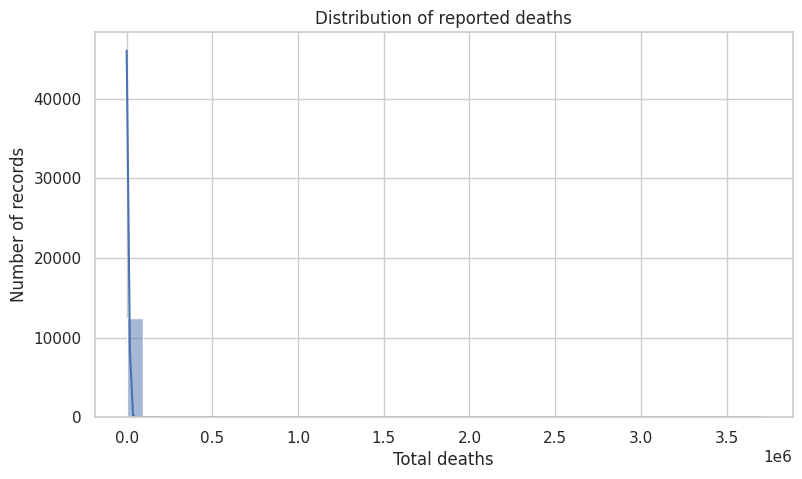

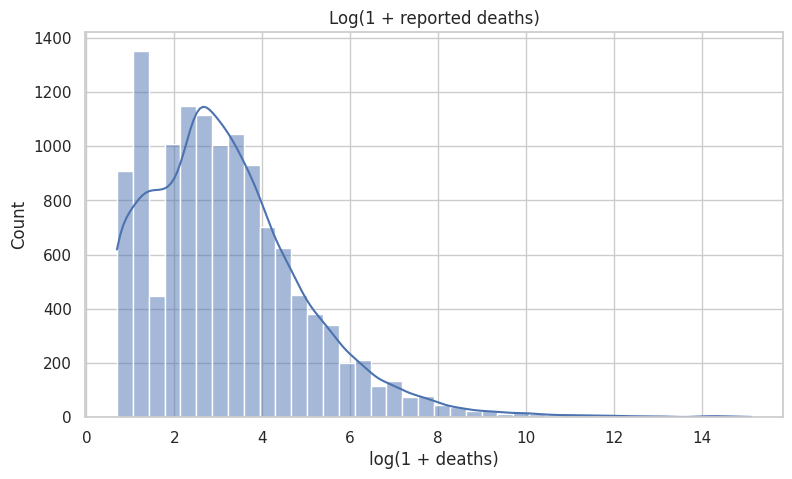

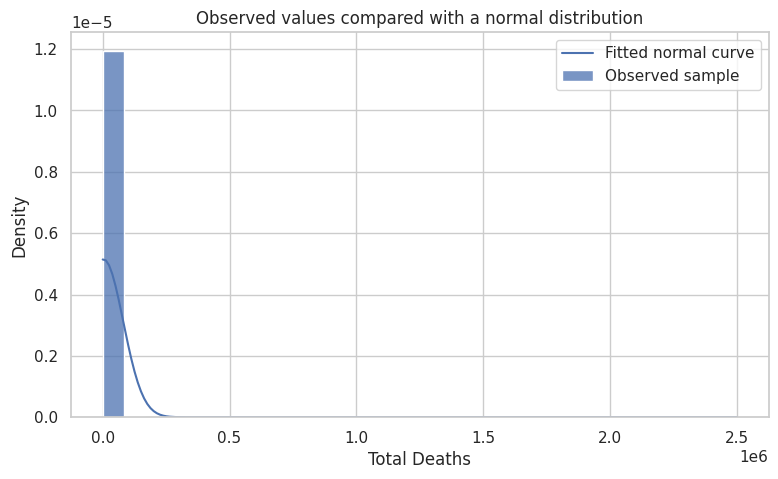

In [ ]:
# 2.2 Distribution, skewness and kurtosis
deaths = df["Total Deaths"].dropna().clip(lower=0)
print("Skewness:", deaths.skew(), "Kurtosis:", deaths.kurtosis())
plt.figure(figsize=(9,5))
sns.histplot(deaths, bins=40, kde=True)
plt.title("Distribution of reported deaths")
plt.xlabel("Total deaths"); plt.ylabel("Number of records"); plt.show()

plt.figure(figsize=(9,5))
sns.histplot(np.log1p(deaths), bins=40, kde=True)
plt.title("Log(1 + reported deaths)")
plt.xlabel("log(1 + deaths)"); plt.show()

sample = deaths.sample(min(2000, len(deaths)), random_state=42) if len(deaths) else deaths
if len(sample) > 2 and sample.std() > 0:
    x = np.linspace(sample.min(), sample.max(), 200)
    plt.figure(figsize=(9,5))
    sns.histplot(sample, stat="density", bins=30, label="Observed sample")
    plt.plot(x, stats.norm.pdf(x, sample.mean(), sample.std()), label="Fitted normal curve")
    plt.title("Observed values compared with a normal distribution")
    plt.legend(); plt.show()

,Total Deaths,No. Injured,No. Affected,No. Homeless,Total Affected,"Total Damage, Adjusted ('000 US$)",Magnitude
Total Deaths,1.000000,0.247438,0.139308,0.163102,0.136854,0.061506,-0.009600
No. Injured,0.247438,1.000000,0.142264,0.414843,0.142762,0.220222,0.010028
No. Affected,0.139308,0.142264,1.000000,0.760165,0.999691,0.131520,0.155720
No. Homeless,0.163102,0.414843,0.760165,1.000000,0.670908,0.182833,0.065053
Total Affected,0.136854,0.142762,0.999691,0.670908,1.000000,0.128661,0.097155
"Total Damage, Adjusted ('000 US$)",0.061506,0.220222,0.131520,0.182833,0.128661,1.000000,-0.001138
Magnitude,-0.009600,0.010028,0.155720,0.065053,0.097155,-0.001138,1.000000


,Total Deaths,No. Injured,No. Affected,No. Homeless,Total Affected,"Total Damage, Adjusted ('000 US$)",Magnitude
Total Deaths,4.296605e+09,6.162018e+07,2.522687e+10,5.345949e+08,1.981124e+10,3.078260e+10,-2.117834e+07
No. Injured,6.162018e+07,1.056573e+09,4.943081e+10,6.618549e+09,3.307301e+10,4.625373e+10,1.295725e+08
No. Affected,2.522687e+10,4.943081e+10,6.631434e+13,4.932239e+12,6.690750e+13,1.334047e+13,2.450126e+11
No. Homeless,5.345949e+08,6.618549e+09,4.932239e+12,2.639401e+11,2.631473e+12,1.244639e+12,4.223169e+09
Total Affected,1.981124e+10,3.307301e+10,6.690750e+13,2.631473e+12,5.431960e+13,1.150391e+13,1.958462e+11
"Total Damage, Adjusted ('000 US$)",3.078260e+10,4.625373e+10,1.334047e+13,1.244639e+12,1.150391e+13,5.502917e+13,-1.992759e+09
Magnitude,-2.117834e+07,1.295725e+08,2.450126e+11,4.223169e+09,1.958462e+11,-1.992759e+09,5.380782e+10


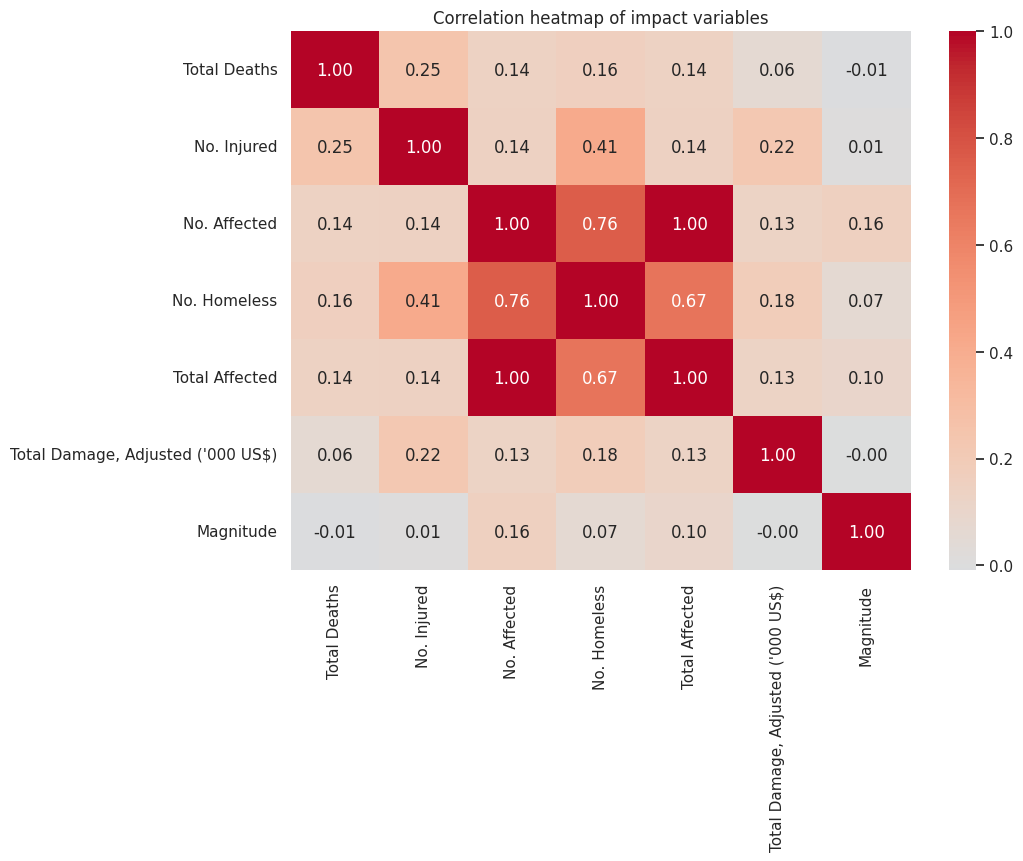

In [ ]:
# 2.3 Correlation and covariance
corr_cols = [c for c in [
    "Total Deaths","No. Injured","No. Affected","No. Homeless",
    "Total Affected","Total Damage, Adjusted ('000 US$)","Magnitude"
] if c in df.columns]
display(df[corr_cols].corr())
display(df[corr_cols].cov())
plt.figure(figsize=(10,7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of impact variables"); plt.show()

In [ ]:
# Welch t-test: compare log deaths for the two most common disaster types
top_types = df["Disaster Type"].value_counts().head(2).index.tolist()
print("Groups:", top_types)
if len(top_types) == 2:
    g1 = np.log1p(df.loc[df["Disaster Type"] == top_types[0], "Total Deaths"].dropna().clip(lower=0))
    g2 = np.log1p(df.loc[df["Disaster Type"] == top_types[1], "Total Deaths"].dropna().clip(lower=0))
    if len(g1) >= 2 and len(g2) >= 2:
        t, p = stats.ttest_ind(g1, g2, equal_var=False)
        print("Welch t statistic:", t, "p-value:", p)
        print("At 5% level:", "Reject H0" if p < .05 else "Do not reject H0")
    else:
        print("Insufficient observations for test.")

Groups: ['Flood', 'Storm']
Welch t statistic: 3.1939278743085726 p-value: 0.00140924360717112
At 5% level: Reject H0


In [ ]:
# Chi-square test: disaster type versus region
ct = pd.crosstab(df["Disaster Type"], df["Region"])
ct = ct.loc[ct.sum(axis=1).nlargest(min(8,len(ct))).index,
            ct.sum(axis=0).nlargest(min(8,len(ct.columns))).index]
chi2, p, dof, expected = stats.chi2_contingency(ct)
print("Chi-square:", chi2, "p-value:", p, "degrees of freedom:", dof)
display(ct)

Chi-square: 4439.015217954536 p-value: 0.0 degrees of freedom: 28


Region,Asia,Americas,Africa,Europe,Oceania
Disaster Type,,,,,
Flood,2505,1405,1268,710,161
Storm,2026,1610,334,602,326
Earthquake,956,326,75,204,58
Epidemic,353,185,911,40,26
Mass movement (wet),456,207,76,85,23
Drought,184,170,360,47,35
Extreme temperature,217,118,22,363,8
Wildfire,75,206,39,127,41


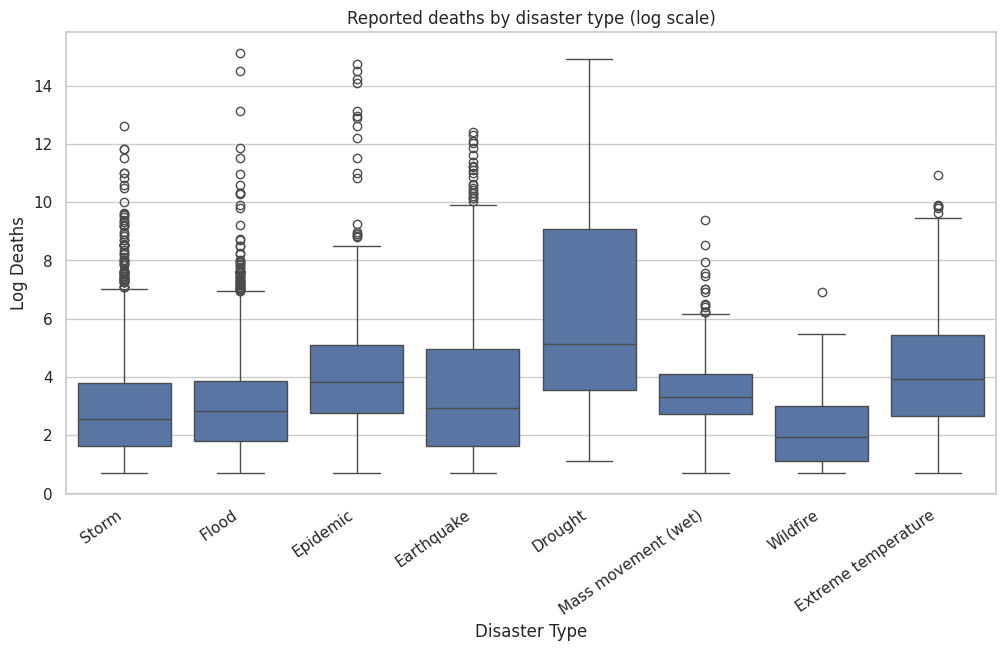

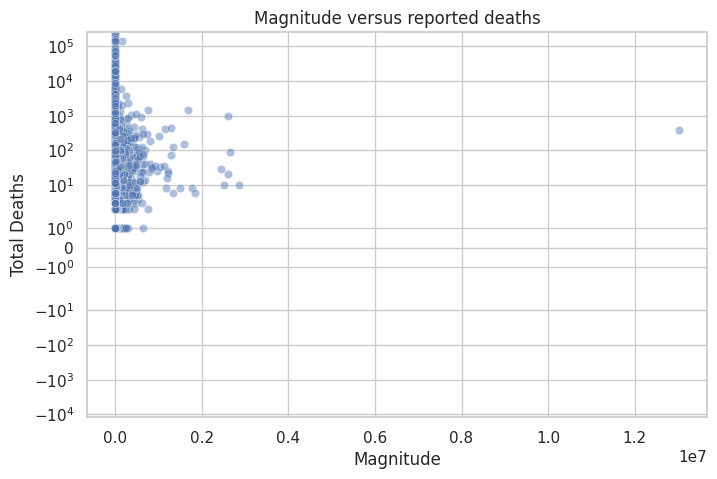

In [ ]:
# 2.4 Box plot
top = df["Disaster Type"].value_counts().head(8).index
plot_df = df[df["Disaster Type"].isin(top)].copy()
plot_df["Log Deaths"] = np.log1p(plot_df["Total Deaths"].clip(lower=0))
plt.figure(figsize=(12,6))
sns.boxplot(data=plot_df, x="Disaster Type", y="Log Deaths")
plt.title("Reported deaths by disaster type (log scale)")
plt.xticks(rotation=35, ha="right"); plt.show()

# Scatter plot
sc = df[["Magnitude","Total Deaths"]].dropna()
sc = sc[(sc["Magnitude"] >= 0) & (sc["Total Deaths"] >= 0)]
plt.figure(figsize=(8,5))
sns.scatterplot(data=sc, x="Magnitude", y="Total Deaths", alpha=.45)
plt.yscale("symlog")
plt.title("Magnitude versus reported deaths"); plt.show()

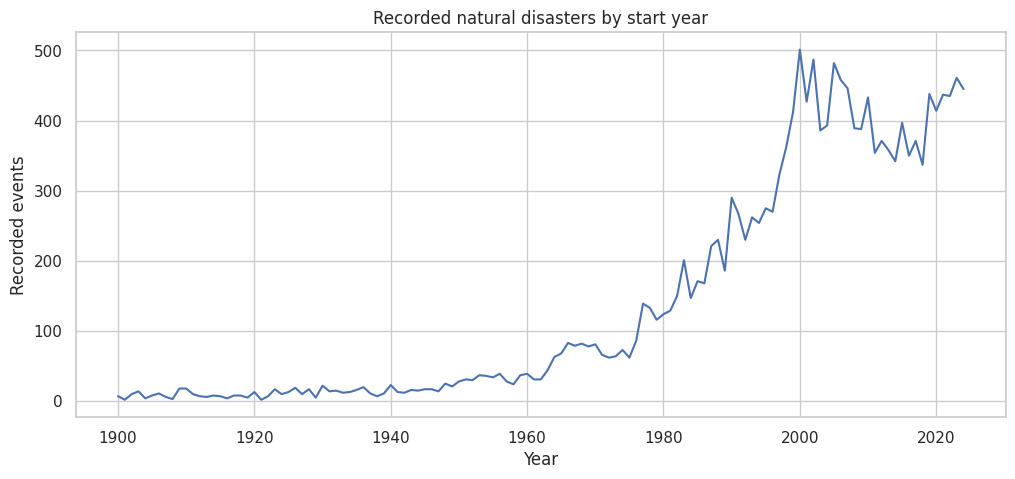

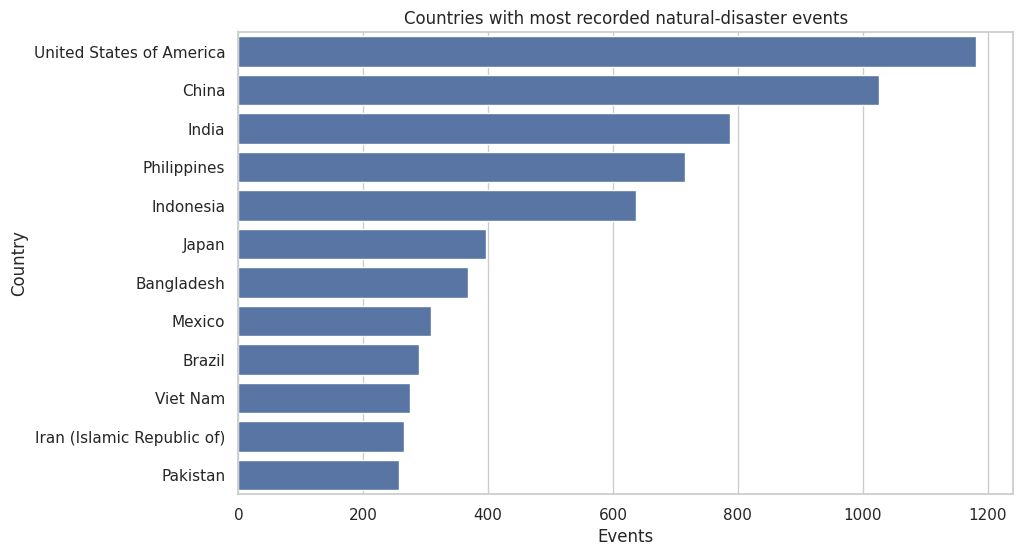

In [ ]:
# 2.5 Year-wise trend and top countries
year_counts = df.groupby("Start Year").size().sort_index()
plt.figure(figsize=(12,5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Recorded natural disasters by start year")
plt.xlabel("Year"); plt.ylabel("Recorded events"); plt.show()

country_counts = df["Country"].value_counts().head(12)
plt.figure(figsize=(10,6))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Countries with most recorded natural-disaster events")
plt.xlabel("Events"); plt.ylabel("Country"); plt.show()

In [ ]:
# 2.6 Univariate, bivariate and multivariate analysis
display(df["Disaster Type"].value_counts().head(15).to_frame("Count"))
display(df.groupby("Disaster Type")["Total Deaths"].median().dropna()
        .sort_values(ascending=False).head(12).to_frame("Median deaths"))
pivot_eda = df.pivot_table(index="Disaster Type", columns="Region",
                           values="Total Deaths", aggfunc="median")
display(pivot_eda.head(12))

,Count
Disaster Type,
Flood,6049
Storm,4898
Earthquake,1619
Epidemic,1515
Mass movement (wet),847
Drought,796
Extreme temperature,728
Wildfire,488
Volcanic activity,278


,Median deaths
Disaster Type,
Fog,4000.0
Drought,171.5
Glacial lake outburst flood,97.0
Extreme temperature,50.0
Epidemic,44.0
Mass movement (dry),38.0
Volcanic activity,37.0
Mass movement (wet),26.0
Earthquake,18.0


Region,Africa,Americas,Asia,Europe,Oceania
Disaster Type,,,,,
Animal incident,12.0,NaN,NaN,NaN,NaN
Drought,302.0,20.0,290.0,600001.0,60.0
Earthquake,11.0,12.0,23.0,14.0,11.0
Epidemic,47.0,19.0,53.0,20.0,19.5
Extreme temperature,21.5,43.0,72.0,49.0,17.0
Flood,13.0,11.0,25.0,4.0,3.5
Fog,NaN,NaN,NaN,4000.0,NaN
Glacial lake outburst flood,NaN,NaN,178.0,11.0,NaN
Mass movement (dry),32.5,34.5,45.5,29.0,43.0


# MODULE 3 — Data Preprocessing and Feature Engineering

### 3.1 Data quality
Check missing values, duplicates and inconsistent text.

### 3.2 Missing-value handling
Demonstrate median imputation for numerical columns and mode imputation for categorical columns. Preserve the original dataset and never interpret missing impacts as zero.

### 3.3 Outlier detection
Use IQR fences and Z-scores. Extreme disaster impacts may be genuine events; flag them rather than automatically deleting them.

### 3.4 Data wrangling
Demonstrate merge/join, concatenation, grouping and pivot tables.

### 3.5 Transformation
Demonstrate min-max normalisation, standardisation and one-hot encoding.

### 3.6 Feature selection and PCA
Demonstrate filter, wrapper and embedded feature selection, followed by PCA.

In [ ]:
# 3.1 Data quality
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate disaster IDs:", df["DisNo."].duplicated().sum())
missing_report = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percent": (df.isna().mean()*100).round(2)
}).sort_values("Missing percent", ascending=False)
display(missing_report.head(25))

for c in ["Country","Region","Disaster Type","Disaster Subtype","Disaster Subgroup"]:
    df[c] = df[c].astype("string").str.strip()

Duplicate rows: 0
Duplicate disaster IDs: 0


,Missing count,Missing percent
"Reconstruction Costs, Adjusted ('000 US$)",17327,99.77
Reconstruction Costs ('000 US$),17327,99.77
AID Contribution ('000 US$),16592,95.54
"Insured Damage, Adjusted ('000 US$)",16230,93.45
Insured Damage ('000 US$),16230,93.45
River Basin,15787,90.90
No. Homeless,14837,85.43
Latitude,14560,83.84
Longitude,14560,83.84
Associated Types,13273,76.43


In [ ]:
# 3.2 Imputation demonstration on a separate copy
impute_demo = df[["Magnitude","Total Deaths","Disaster Type","Region"]].copy()
for c in ["Magnitude","Total Deaths"]:
    impute_demo[c] = impute_demo[c].fillna(impute_demo[c].median())
for c in ["Disaster Type","Region"]:
    impute_demo[c] = impute_demo[c].fillna(impute_demo[c].mode().iloc[0])
display(impute_demo.isna().sum().to_frame("Missing after imputation"))

,Missing after imputation
Magnitude,0
Total Deaths,0
Disaster Type,0
Region,0


IQR fences: -78.0 146.0
IQR outlier count: 1815
Z-score outlier count (|z|>3): 23


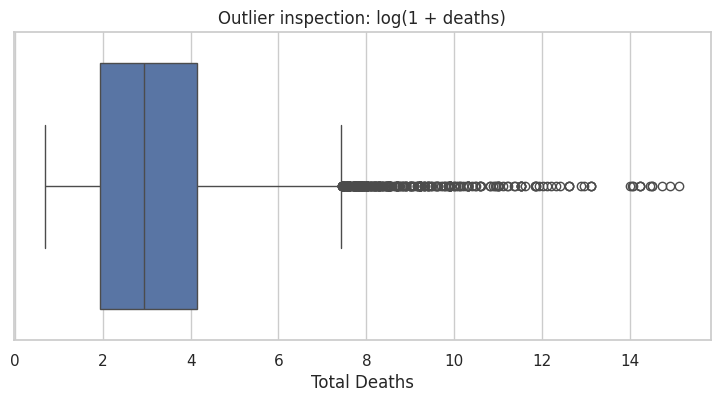

In [ ]:
# 3.3 IQR and Z-score outlier detection
s = df["Total Deaths"].dropna()
q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
lo, hi = q1-1.5*iqr, q3+1.5*iqr
print("IQR fences:", lo, hi)
print("IQR outlier count:", ((s<lo)|(s>hi)).sum())
z = stats.zscore(s)
print("Z-score outlier count (|z|>3):", (np.abs(z)>3).sum())
plt.figure(figsize=(9,4))
sns.boxplot(x=np.log1p(s.clip(lower=0)))
plt.title("Outlier inspection: log(1 + deaths)"); plt.show()

In [ ]:
# 3.4 Merge/join, concatenation, grouping and pivot table
country_summary = df.groupby("Country", as_index=False).agg(
    Recorded_Events=("DisNo.","count"), Median_Deaths=("Total Deaths","median"))
merge_demo = df[["DisNo.","Country","Disaster Type"]].merge(
    country_summary, on="Country", how="left")
display(merge_demo.head())

half = len(df)//2
concat_demo = pd.concat([df.iloc[:half], df.iloc[half:]], ignore_index=True)
print("Original and concatenated shapes:", df.shape, concat_demo.shape)

display(df.groupby(["Region","Disaster Type"]).size().to_frame("Events").head(20))
display(pd.pivot_table(df, index="Region", columns="Disaster Type",
                       values="DisNo.", aggfunc="count", fill_value=0).head())

,DisNo.,Country,Disaster Type,Recorded_Events,Median_Deaths
0,1900-0003-USA,United States of America,Storm,1182,11.0
1,1900-0006-JAM,Jamaica,Flood,58,9.5
2,1900-0007-JAM,Jamaica,Epidemic,58,9.5
3,1900-0008-JPN,Japan,Volcanic activity,396,26.0
4,1900-0009-TUR,Türkiye,Earthquake,211,23.0


Original and concatenated shapes: (17367, 48) (17367, 48)


Events
Region   Disaster Type              
Africa   Animal incident           1
         Drought                 360
         Earthquake               75
         Epidemic                911
         Extreme temperature      22
         Flood                  1268
         Infestation              77
         Mass movement (dry)       6
         Mass movement (wet)      76
         Storm                   334
         Volcanic activity        20
         Wildfire                 39
Americas Drought                 170
         Earthquake              326
         Epidemic                185
         Extreme temperature     118
         Flood                  1405
         Infestation               3
         Mass movement (dry)      13
         Mass movement (wet)     207

Disaster Type,Animal incident,Drought,Earthquake,Epidemic,Extreme temperature,Flood,Fog,Glacial lake outburst flood,Impact,Infestation,Mass movement (dry),Mass movement (wet),Storm,Volcanic activity,Wildfire
Region,,,,,,,,,,,,,,,
Africa,1,360,75,911,22,1268,0,0,0,77,6,76,334,20,39
Americas,0,170,326,185,118,1405,0,0,0,3,13,207,1610,96,206
Asia,0,184,956,353,217,2505,0,4,0,12,22,456,2026,117,75
Europe,0,47,204,40,363,710,1,1,1,1,3,85,602,12,127
Oceania,0,35,58,26,8,161,0,0,0,2,2,23,326,33,41


In [ ]:
# 3.5 Normalisation, standardisation and categorical encoding
from sklearn.preprocessing import MinMaxScaler, StandardScaler
scale_cols = [c for c in ["Magnitude","Total Deaths","Total Affected"] if c in df.columns]
scale_demo = df[scale_cols].copy().fillna(df[scale_cols].median())
minmax_values = MinMaxScaler().fit_transform(scale_demo)
standard_values = StandardScaler().fit_transform(scale_demo)
display(pd.DataFrame(minmax_values, columns=scale_cols).head())
display(pd.DataFrame(standard_values, columns=scale_cols).head())
display(pd.get_dummies(df[["Disaster Type","Region"]].head(10), dtype=int))

,Magnitude,Total Deaths,Total Affected
0,0.000021,0.001621,0.000018
1,0.000016,0.000081,0.000018
2,0.000016,0.000008,0.000018
3,0.000016,0.000008,0.000018
4,0.000005,0.000038,0.000018


,Magnitude,Total Deaths,Total Affected
0,-0.085817,0.073833,-0.0799
1,-0.086376,-0.028627,-0.0799
2,-0.086376,-0.033481,-0.0799
3,-0.086376,-0.033481,-0.0799
4,-0.087480,-0.031503,-0.0799


,Disaster Type_Drought,Disaster Type_Earthquake,Disaster Type_Epidemic,Disaster Type_Flood,Disaster Type_Storm,Disaster Type_Volcanic activity,Region_Africa,Region_Americas,Region_Asia
0,0,0,0,0,1,0,0,1,0
2,0,0,0,1,0,0,0,1,0
3,0,0,1,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1
5,0,1,0,0,0,0,0,0,1
6,1,0,0,0,0,0,0,0,1
7,1,0,0,0,0,0,1,0,0
8,0,0,1,0,0,0,1,0,0
10,0,1,0,0,0,0,0,0,1
12,0,0,0,0,0,1,0,1,0


Filter-selected: ['Start Year', 'Latitude', 'Longitude']
Wrapper-selected: ['Start Year', 'Magnitude', 'Longitude']


,Embedded RF importance
Start Year,0.302762
Longitude,0.218125
Magnitude,0.213625
Latitude,0.177359
Start Month,0.088130


PCA explained variance ratio: [0.27015674 0.20920515]


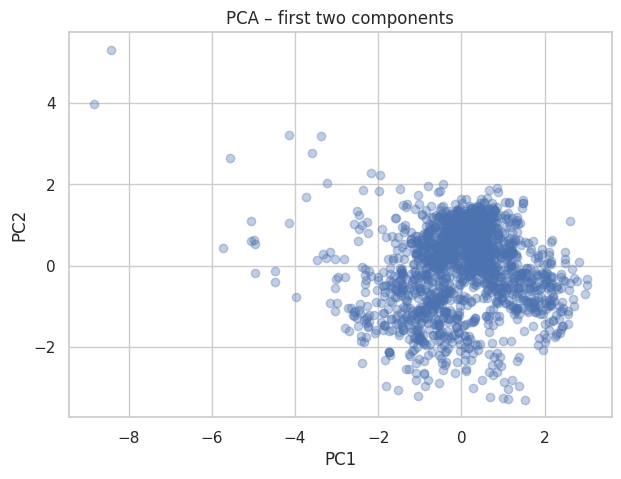

In [ ]:
# 3.6 Filter, wrapper, embedded feature selection and PCA
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA

features = [c for c in ["Start Year","Start Month","Magnitude","Latitude","Longitude"] if c in df.columns]
fs = df[features + ["Total Deaths"]].dropna()
if len(fs) >= 30 and len(features) >= 2:
    Xfs = fs[features]
    yfs = np.log1p(fs["Total Deaths"].clip(lower=0))
    k = min(3, len(features))
    filt = SelectKBest(f_regression, k=k).fit(Xfs, yfs)
    print("Filter-selected:", Xfs.columns[filt.get_support()].tolist())

    rf = RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=-1)
    wrapper = RFE(rf, n_features_to_select=k).fit(Xfs, yfs)
    print("Wrapper-selected:", Xfs.columns[wrapper.get_support()].tolist())

    rf.fit(Xfs, yfs)
    display(pd.Series(rf.feature_importances_, index=features)
            .sort_values(ascending=False).to_frame("Embedded RF importance"))

    Xscaled = StandardScaler().fit_transform(Xfs)
    pcs = PCA(n_components=2).fit_transform(Xscaled)
    print("PCA explained variance ratio:", PCA(n_components=2).fit(Xscaled).explained_variance_ratio_)
    plt.figure(figsize=(7,5)); plt.scatter(pcs[:,0], pcs[:,1], alpha=.35)
    plt.title("PCA – first two components"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()
else:
    print("Not enough complete observations for feature-selection/PCA example.")

# MODULE 4 — Predictive Analytics and Machine Learning Techniques

### 4.1 Introduction
Predictive analytics estimates outcomes using patterns learned from historical data. The models below are for coursework demonstration only.

### 4.2 Regression and classification
- Regression target: log(1 + reported deaths), using event descriptors.
- Classification target: disaster type, using event descriptors.
- Pipelines perform imputation, scaling and encoding using training data only.

### 4.3 K-Means and hierarchical clustering
Group events by selected numerical characteristics. Clusters are mathematical groupings, not official severity classes.

### 4.4 Validation and evaluation
Use train/test split, cross-validation, accuracy, precision, recall, F1-score and confusion matrix. Discuss overfitting and underfitting.

Regression rows: 12505
MAE: 1.1521878127576082
RMSE: 1.5294334658562938
R2: 0.3107493414538788


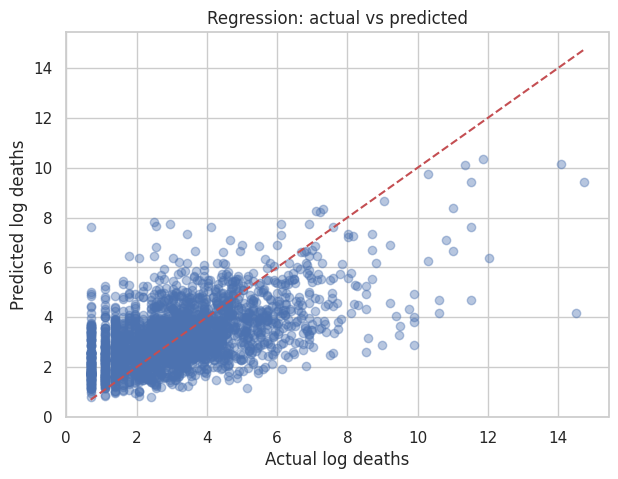

In [ ]:
# 4.2 Regression: estimate log(1 + reported deaths)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    classification_report)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

num_reg = [c for c in ["Start Year","Start Month","Magnitude"] if c in df.columns]
cat_reg = [c for c in ["Disaster Type","Region"] if c in df.columns]
rd = df[num_reg+cat_reg+["Total Deaths"]].copy()
rd["Total Deaths"] = pd.to_numeric(rd["Total Deaths"], errors="coerce")
rd = rd.dropna(subset=["Total Deaths"])
rd = rd[rd["Total Deaths"] >= 0]
print("Regression rows:", len(rd))

if len(rd) >= 50:
    X = rd[num_reg+cat_reg]; y = np.log1p(rd["Total Deaths"])
    num_pipe = Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
    cat_pipe = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                         ("onehot",OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num",num_pipe,num_reg),("cat",cat_pipe,cat_reg)])
    Xtr, Xte, ytr, yte = train_test_split(X,y,test_size=.2,random_state=42)
    reg_model = Pipeline([("prep",prep),("model",RandomForestRegressor(
        n_estimators=120,random_state=42,n_jobs=-1,min_samples_leaf=2))])
    reg_model.fit(Xtr,ytr); pred = reg_model.predict(Xte)
    print("MAE:",mean_absolute_error(yte,pred))
    print("RMSE:",np.sqrt(mean_squared_error(yte,pred)))
    print("R2:",r2_score(yte,pred))
    plt.figure(figsize=(7,5)); plt.scatter(yte,pred,alpha=.4)
    a,b=min(yte.min(),pred.min()),max(yte.max(),pred.max())
    plt.plot([a,b],[a,b],"r--"); plt.xlabel("Actual log deaths")
    plt.ylabel("Predicted log deaths"); plt.title("Regression: actual vs predicted"); plt.show()
else:
    print("Insufficient rows for regression.")

Disaster Type
Flood                  6049
Storm                  4898
Earthquake             1619
Epidemic               1515
Mass movement (wet)     847
Drought                 796
Name: count, dtype: Int64
Accuracy: 0.9116057233704292
Precision macro: 0.8597865946695217
Recall macro: 0.866681337310708
F1 macro: 0.8622197399669926
                     precision    recall  f1-score   support

            Drought       1.00      1.00      1.00       159
         Earthquake       1.00      1.00      1.00       324
           Epidemic       1.00      1.00      1.00       303
              Flood       0.90      0.86      0.88      1210
Mass movement (wet)       0.26      0.34      0.29       169
              Storm       1.00      1.00      1.00       980

           accuracy                           0.91      3145
          macro avg       0.86      0.87      0.86      3145
       weighted avg       0.92      0.91      0.92      3145



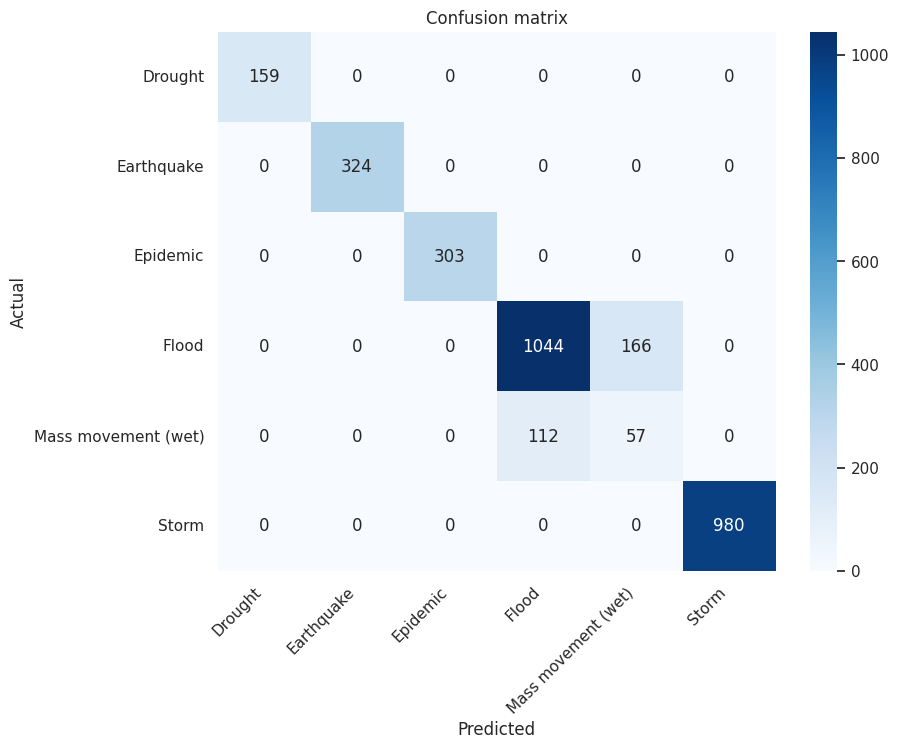

In [ ]:
# 4.2 Classification: predict disaster type from event descriptors
num_clf = [c for c in ["Start Year","Start Month","Magnitude"] if c in df.columns]
cat_clf = [c for c in ["Region","Disaster Subgroup"] if c in df.columns]
cd = df[num_clf+cat_clf+["Disaster Type"]].dropna(subset=["Disaster Type"]).copy()
top_classes = cd["Disaster Type"].value_counts().head(6).index
cd = cd[cd["Disaster Type"].isin(top_classes)]
print(cd["Disaster Type"].value_counts())

if cd["Disaster Type"].nunique() >= 2 and cd["Disaster Type"].value_counts().min() >= 2:
    Xc = cd[num_clf+cat_clf]; yc = cd["Disaster Type"]
    npipe = Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
    cpipe = Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                      ("onehot",OneHotEncoder(handle_unknown="ignore"))])
    cprep = ColumnTransformer([("num",npipe,num_clf),("cat",cpipe,cat_clf)])
    Xtrc,Xtec,ytrc,ytec = train_test_split(Xc,yc,test_size=.2,random_state=42,stratify=yc)
    clf = Pipeline([("prep",cprep),("model",RandomForestClassifier(
        n_estimators=150,random_state=42,class_weight="balanced",n_jobs=-1))])
    clf.fit(Xtrc,ytrc); yhat=clf.predict(Xtec)
    print("Accuracy:",accuracy_score(ytec,yhat))
    print("Precision macro:",precision_score(ytec,yhat,average="macro",zero_division=0))
    print("Recall macro:",recall_score(ytec,yhat,average="macro",zero_division=0))
    print("F1 macro:",f1_score(ytec,yhat,average="macro",zero_division=0))
    print(classification_report(ytec,yhat,zero_division=0))
    labels=clf.named_steps["model"].classes_
    cm=confusion_matrix(ytec,yhat,labels=labels)
    plt.figure(figsize=(9,7)); sns.heatmap(cm,annot=True,fmt="d",
        xticklabels=labels,yticklabels=labels,cmap="Blues")
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix"); plt.xticks(rotation=45,ha="right"); plt.show()
else:
    clf = None
    print("Insufficient examples per class for classification.")

In [ ]:
# 4.3 K-Means and hierarchical clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

cluster_cols = [c for c in ["Start Year","Magnitude","Total Deaths","Total Affected"] if c in df.columns]
cl = df[cluster_cols].copy()
for c in ["Total Deaths","Total Affected"]:
    if c in cl.columns: cl[c] = np.log1p(cl[c].clip(lower=0))
cl = cl.replace([np.inf,-np.inf],np.nan).fillna(cl.median()).dropna()
if len(cl) > 10 and len(cluster_cols) >= 2:
    Xcl = StandardScaler().fit_transform(cl)
    km = KMeans(n_clusters=3,random_state=42,n_init=10)
    labels_km = km.fit_predict(Xcl)
    sample_ids = np.random.RandomState(42).choice(len(Xcl),size=min(2500,len(Xcl)),replace=False)
    print("K-Means silhouette score on sample:",
          silhouette_score(Xcl[sample_ids],labels_km[sample_ids]))
    hcl = AgglomerativeClustering(n_clusters=3,linkage="ward")
    labels_h = hcl.fit_predict(Xcl[sample_ids])
    print("Hierarchical clustering completed on",len(sample_ids),"sampled events.")
    cl_result=cl.copy(); cl_result["KMeans Cluster"]=labels_km
    display(cl_result.groupby("KMeans Cluster").mean())
else:
    print("Insufficient data for clustering.")

K-Means silhouette score on sample: 0.3369025679589047
Hierarchical clustering completed on 2500 sampled events.


,Start Year,Magnitude,Total Deaths,Total Affected
KMeans Cluster,,,,
0,1982.961867,1.484787e+04,4.556623,10.844176
1,2005.860190,8.628192e+03,2.513300,7.922944
2,2015.000000,1.302587e+07,5.953243,8.433812


In [ ]:
# 4.4 Cross-validation and overfitting/underfitting discussion
if clf is not None:
    min_count = yc.value_counts().min()
    folds = min(5,int(min_count))
    if folds >= 2:
        cv = StratifiedKFold(n_splits=folds,shuffle=True,random_state=42)
        scores = cross_val_score(clf,Xc,yc,cv=cv,scoring="f1_macro",n_jobs=-1)
        print("CV macro F1 scores:",scores)
        print("Mean CV macro F1:",scores.mean())
else:
    print("Run the classification cell successfully before cross-validation.")

print("Overfitting: strong training performance but weak unseen-data performance.")
print("Underfitting: model is too simple and performs poorly on both training and test data.")
print("Mitigation: cross-validation, simpler models, regularisation and complexity controls.")

CV macro F1 scores: [0.86714168 0.86236608 0.86653398 0.86579215 0.86336163]
Mean CV macro F1: 0.8650391042424881
Overfitting: strong training performance but weak unseen-data performance.
Underfitting: model is too simple and performs poorly on both training and test data.
Mitigation: cross-validation, simpler models, regularisation and complexity controls.


# MODULE 5 — Data Visualization and Dashboard Development with Case Studies

### 5.1 Principles
Use clear labels, readable scales, accessible colour contrast and an appropriate chart type. Avoid 3D effects, unnecessary decoration and truncated axes that exaggerate differences. Disclose missingness and uncertainty.

### 5.2 Matplotlib subplots/annotations, Seaborn advanced plots and Plotly interactive charts

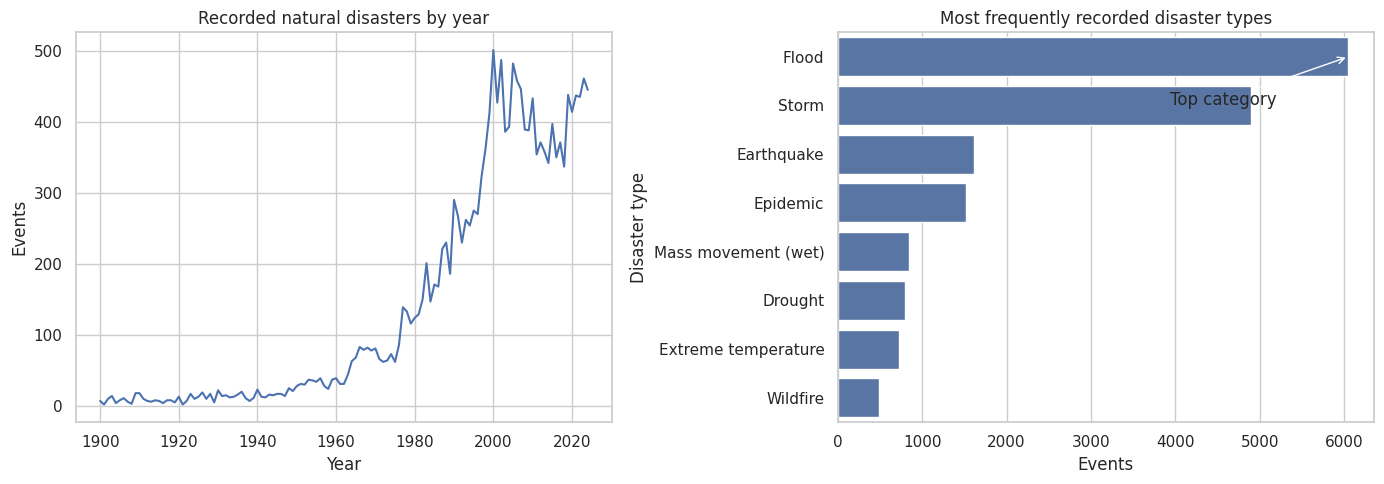

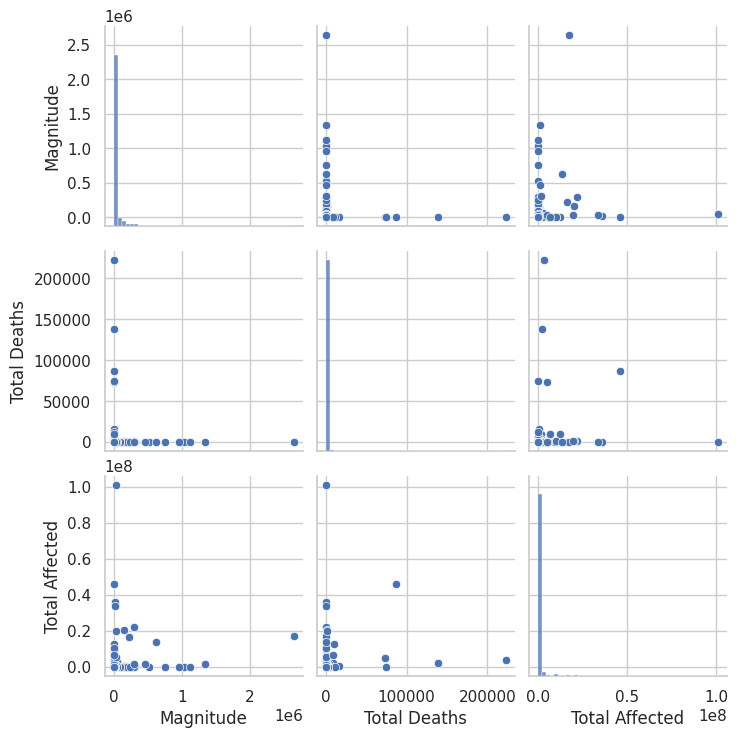

In [ ]:
# Matplotlib subplots and annotation
fig, axes = plt.subplots(1,2,figsize=(14,5))
year_counts.plot(ax=axes[0])
axes[0].set_title("Recorded natural disasters by year")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Events")
tc=df["Disaster Type"].value_counts().head(8)
sns.barplot(x=tc.values,y=tc.index,ax=axes[1])
axes[1].set_title("Most frequently recorded disaster types")
axes[1].set_xlabel("Events"); axes[1].set_ylabel("Disaster type")
axes[1].annotate("Top category",xy=(tc.iloc[0],0),
                 xytext=(tc.iloc[0]*.65,1),arrowprops={"arrowstyle":"->"})
plt.tight_layout(); plt.show()

# Seaborn pairplot
pair_cols=[c for c in ["Magnitude","Total Deaths","Total Affected"] if c in df.columns]
pair=df[pair_cols].dropna()
if len(pair)>2 and len(pair_cols)>=2:
    sns.pairplot(pair.sample(min(500,len(pair)),random_state=42))
    plt.show()

In [ ]:
# Plotly interactive charts
import plotly.express as px
year_plot=year_counts.rename_axis("Year").reset_index(name="Recorded Events")
px.line(year_plot,x="Year",y="Recorded Events",markers=True,
        title="Interactive: recorded natural disasters by year").show()
type_region=df.groupby(["Disaster Type","Region"]).size().reset_index(name="Events")
px.bar(type_region,x="Disaster Type",y="Events",color="Region",
       title="Interactive: disaster events by type and region").show()

### 5.3 Streamlit interactive dashboard
This cell writes a simple Streamlit app with file upload, sidebar filters, KPI cards and Plotly charts. Download the generated files and run locally:
```bash
pip install streamlit pandas plotly
streamlit run disaster_dashboard.py
```
Upload `natural_disasters_clean.csv` in the app. Streamlit is a web application, so this local workflow is simpler than hosting it inside Colab.

In [ ]:
# Export dashboard data and create Streamlit app source
dashboard_cols=[c for c in [
    "DisNo.","Country","Region","Disaster Type","Disaster Subtype",
    "Start Year","Start Month","Total Deaths","Total Affected",
    "Total Damage, Adjusted ('000 US$)","Magnitude"
] if c in df.columns]
df[dashboard_cols].to_csv("natural_disasters_clean.csv",index=False)

app = '''
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title="DisasterScope",layout="wide")
st.title("DisasterScope – Natural Disaster Analytics")
st.caption("Exploratory analysis of historical EM-DAT records.")
uploaded=st.file_uploader("Upload natural_disasters_clean.csv",type=["csv"])
if uploaded is None:
    st.info("Upload the exported CSV to view the dashboard.")
    st.stop()
data=pd.read_csv(uploaded)
if "Region" in data:
    opts=sorted(data["Region"].dropna().unique())
    selected=st.sidebar.multiselect("Region",opts,default=opts)
    data=data[data["Region"].isin(selected)]
if "Disaster Type" in data:
    opts=sorted(data["Disaster Type"].dropna().unique())
    selected=st.sidebar.multiselect("Disaster type",opts,default=opts)
    data=data[data["Disaster Type"].isin(selected)]
a,b,c=st.columns(3)
a.metric("Recorded events",f"{len(data):,}")
b.metric("Countries",f"{data['Country'].nunique():,}" if "Country" in data else "N/A")
c.metric("Reported deaths",f"{data['Total Deaths'].sum(skipna=True):,.0f}" if "Total Deaths" in data else "N/A")
if "Start Year" in data:
    annual=data.groupby("Start Year").size().reset_index(name="Events")
    st.plotly_chart(px.line(annual,x="Start Year",y="Events",markers=True),use_container_width=True)
if "Disaster Type" in data:
    counts=data["Disaster Type"].value_counts().reset_index()
    counts.columns=["Disaster Type","Events"]
    st.plotly_chart(px.bar(counts,x="Disaster Type",y="Events"),use_container_width=True)
if "Country" in data and "Total Deaths" in data:
    country=data.groupby("Country",as_index=False)["Total Deaths"].sum().nlargest(15,"Total Deaths")
    st.plotly_chart(px.bar(country,x="Total Deaths",y="Country",orientation="h"),use_container_width=True)
st.subheader("Filtered records")
st.dataframe(data,use_container_width=True)
'''
with open("disaster_dashboard.py","w") as f: f.write(app)
print("Created natural_disasters_clean.csv and disaster_dashboard.py")

Created natural_disasters_clean.csv and disaster_dashboard.py


In [ ]:
files.download("natural_disasters_clean.csv")
files.download("disaster_dashboard.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.4 Tableau and Power BI
The exported `natural_disasters_clean.csv` can be loaded into Tableau or Power BI. Suggested practical tasks:
1. Connect to the CSV.
2. Create a KPI card for event count.
3. Create a bar chart for disaster type.
4. Create a line chart for events by year.
5. Add region and disaster-type filters.
6. Save/publish the dashboard using the application.
This notebook prepares the compatible data but does not claim to publish a Tableau or Power BI dashboard.

### 5.5 Case studies and responsible data analytics
The EM-DAT case study is disaster-risk and humanitarian impact analytics, not a healthcare, retail-sales or financial-sales dataset. The same workflow transfers to:
- Healthcare: patient outcomes and resource demand (with authorised, protected data).
- Retail: sales by product, date, store and segment.
- Finance: transaction patterns, credit risk and portfolio performance.
- Responsible analytics: disclose uncertainty, protect sensitive data, avoid unsupported causal claims and communicate missing data honestly.

For EM-DAT, do not treat unreported deaths or damage as zero, and do not rank countries without considering differences in reporting coverage.

## Final summary and viva preparation

In [ ]:
print("Source rows:",len(raw))
print("Natural disaster rows:",len(df))
print("Countries:",df["Country"].nunique())
print("Disaster types:",df["Disaster Type"].nunique())
print("Year range:",df["Start Year"].min(),"-",df["Start Year"].max())
print("\nLimitations:")
print("1. EM-DAT is a recorded-event database; reporting completeness varies.")
print("2. Many impact/economic fields contain missing values.")
print("3. Missing values do not mean zero impact.")
print("4. Event-level data is not a regular daily time series.")
print("5. Models are exploratory, not operational early-warning systems.")

Source rows: 26946
Natural disaster rows: 17367
Countries: 230
Disaster types: 15
Year range: 1900 - 2024

Limitations:
1. EM-DAT is a recorded-event database; reporting completeness varies.
2. Many impact/economic fields contain missing values.
3. Missing values do not mean zero impact.
4. Event-level data is not a regular daily time series.
5. Models are exploratory, not operational early-warning systems.


### Viva questions
1. What does EM-DAT stand for?
2. What are the four types of analytics?
3. Why should missing impacts not automatically be replaced with zero?
4. Explain IQR and Z-score outlier detection.
5. Why standardise before K-Means and PCA?
6. Differentiate regression and classification.
7. Explain accuracy, precision, recall and F1-score.
8. What are train/test split and cross-validation?
9. What is PCA?
10. How do Plotly and Matplotlib differ?
11. What are the limitations of EM-DAT?

## Data provenance
The analysis uses the EM-DAT archive and optional column dictionary uploaded for this project. Consult the archive's documentation for field definitions and data-vintage details.

**End of DisasterScope DAES notebook.**